Training YOUR 4 Mudras: Alapadmam | Shikaram | Chandrakala | Kapitham
Removed 0 corrupt images
Class counts: {'Alapadmam': 1314, 'Chandrakala': 1172, 'Kapitham': 1150, 'Shikaram': 1179}


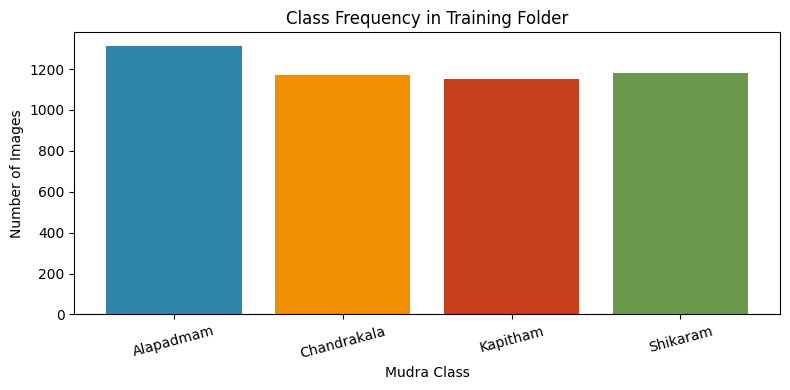

Found 4815 files belonging to 4 classes.
Using 3852 files for training.
Found 4815 files belonging to 4 classes.
Using 963 files for validation.
✅ Found classes: ['Alapadmam', 'Chandrakala', 'Kapitham', 'Shikaram']


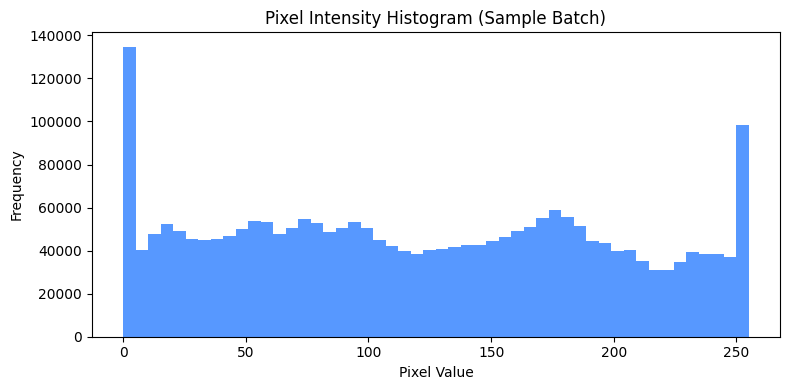


 Phase 1: Training top layers...
Epoch 1/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 95s 296ms/step - accuracy: 0.7638 - loss: 0.6118 - val_accuracy: 0.9138 - val_loss: 0.2683
Epoch 2/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 67s 279ms/step - accuracy: 0.9169 - loss: 0.2380 - val_accuracy: 0.9408 - val_loss: 0.1818
Epoch 3/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 66s 274ms/step - accuracy: 0.9372 - loss: 0.1838 - val_accuracy: 0.9543 - val_loss: 0.1525
Epoch 4/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 75s 313ms/step - accuracy: 0.9465 - loss: 0.1558 - val_accuracy: 0.9502 - val_loss: 0.1384
Epoch 5/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 71s 297ms/step - accuracy: 0.9561 - loss: 0.1361 - val_accuracy: 0.9574 - val_loss: 0.1126
Epoch 6/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 71s 294ms/step - accuracy: 0.9616 - loss: 0.1169 - val_accuracy: 0.9626 - val_loss: 0.1054
Epoch 7/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 72s 297ms/step - accuracy: 0.9621 - loss: 0.1097 - val_accuracy: 0.9709 - val_loss: 0.0821
Epoch 8/10
241/241 ━━━━━━━━━━━━━━━━━━━━ 76s 314ms

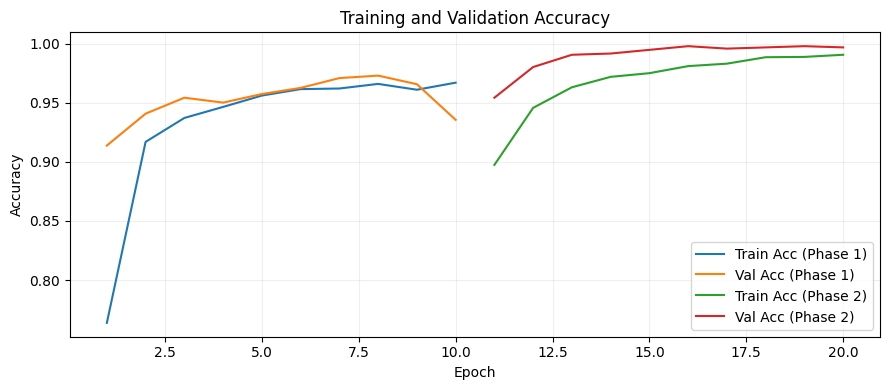

mudra_model.keras SAVED! 


In [2]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

print("Training YOUR 4 Mudras: Alapadmam | Shikaram | Chandrakala | Kapitham")

IMG_SIZE = (224, 224)
BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE
SEED = 123
TRAIN_DIR = Path("train")


def remove_corrupt_images(root_dir: Path):
    """Delete unreadable image files so dataset loading is stable."""
    valid_ext = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    removed = []

    for file_path in root_dir.rglob("*"):
        if not file_path.is_file() or file_path.suffix.lower() not in valid_ext:
            continue

        try:
            image_bytes = tf.io.read_file(str(file_path))
            tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
        except Exception:
            removed.append(str(file_path))
            file_path.unlink(missing_ok=True)

    print(f"Removed {len(removed)} corrupt images")
    return removed


def get_class_counts(root_dir: Path):
    counts = {}
    for class_dir in sorted([p for p in root_dir.iterdir() if p.is_dir()]):
        image_count = sum(
            1 for p in class_dir.iterdir() if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
        )
        counts[class_dir.name] = image_count
    return counts



remove_corrupt_images(TRAIN_DIR)


class_counts = get_class_counts(TRAIN_DIR)
print("Class counts:", class_counts)

plt.figure(figsize=(8, 4))
plt.bar(class_counts.keys(), class_counts.values(), color=["#2E86AB", "#F18F01", "#C73E1D", "#6A994E"])
plt.title("Class Frequency in Training Folder")
plt.xlabel("Mudra Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


train_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    validation_split=0.2,
    subset='training',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)
val_ds = tf.keras.utils.image_dataset_from_directory(
    str(TRAIN_DIR),
    validation_split=0.2,
    subset='validation',
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
)

class_names = train_ds.class_names
print(f"✅ Found classes: {class_names}")


sample_images, _ = next(iter(train_ds.take(1)))
sample_pixels = tf.reshape(sample_images, [-1]).numpy()

plt.figure(figsize=(8, 4))
plt.hist(sample_pixels, bins=50, color="#3A86FF", alpha=0.85)
plt.title("Pixel Intensity Histogram (Sample Batch)")
plt.xlabel("Pixel Value")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.15),
    tf.keras.layers.RandomZoom(0.15),
    tf.keras.layers.RandomBrightness(0.1),
])


base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)
base_model.trainable = False

# Build model
inputs = tf.keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(4, activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Improve input pipeline speed
train_ds = train_ds.cache().shuffle(1000).prefetch(AUTOTUNE)
val_ds = val_ds.cache().prefetch(AUTOTUNE)

# Phase 1: Train top layers only
print("\n Phase 1: Training top layers...")
history = model.fit(train_ds, validation_data=val_ds, epochs=10)

# Phase 2: Fine-tune top 50 layers of MobileNetV2
print("\n Phase 2: Fine-tuning MobileNetV2 top layers...")
base_model.trainable = True
for layer in base_model.layers[:-50]:
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
history2 = model.fit(train_ds, validation_data=val_ds, epochs=10)

# 4) Plot training and validation accuracy across both phases
acc_phase1 = history.history.get("accuracy", [])
val_acc_phase1 = history.history.get("val_accuracy", [])
acc_phase2 = history2.history.get("accuracy", [])
val_acc_phase2 = history2.history.get("val_accuracy", [])

epochs_phase1 = np.arange(1, len(acc_phase1) + 1)
epochs_phase2 = np.arange(len(acc_phase1) + 1, len(acc_phase1) + len(acc_phase2) + 1)

plt.figure(figsize=(9, 4))
plt.plot(epochs_phase1, acc_phase1, label="Train Acc (Phase 1)", color="#1f77b4")
plt.plot(epochs_phase1, val_acc_phase1, label="Val Acc (Phase 1)", color="#ff7f0e")
if len(acc_phase2) > 0:
    plt.plot(epochs_phase2, acc_phase2, label="Train Acc (Phase 2)", color="#2ca02c")
    plt.plot(epochs_phase2, val_acc_phase2, label="Val Acc (Phase 2)", color="#d62728")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

model.save('mudra_model.keras')
print("mudra_model.keras SAVED! ")


📊 Evaluating with visual metrics on validation split...
Overall validation accuracy: 99.69%

Confusion matrix:
[[229   1   0   0]
 [  0 245   0   2]
 [  0   0 235   0]
 [  0   0   0 251]]

Alapadmam: 229/230 correct (99.57%)
Chandrakala: 245/247 correct (99.19%)
Kapitham: 235/235 correct (100.00%)
Shikaram: 251/251 correct (100.00%)


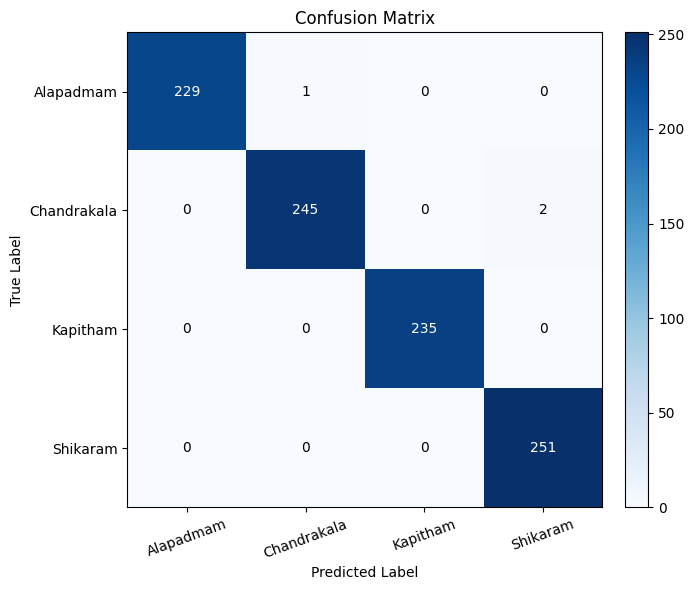

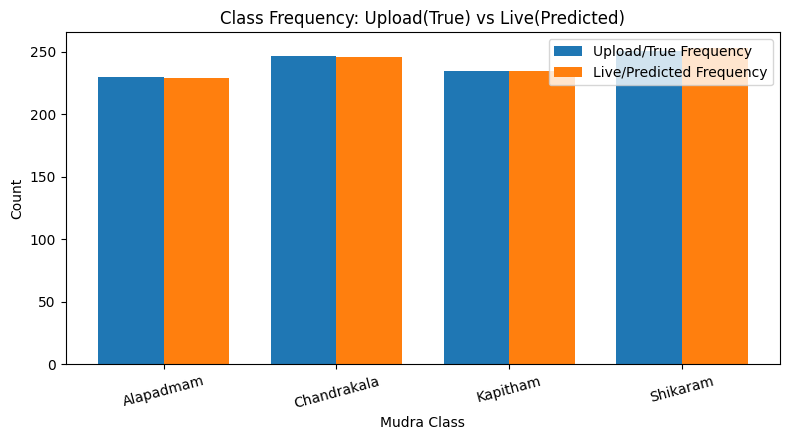

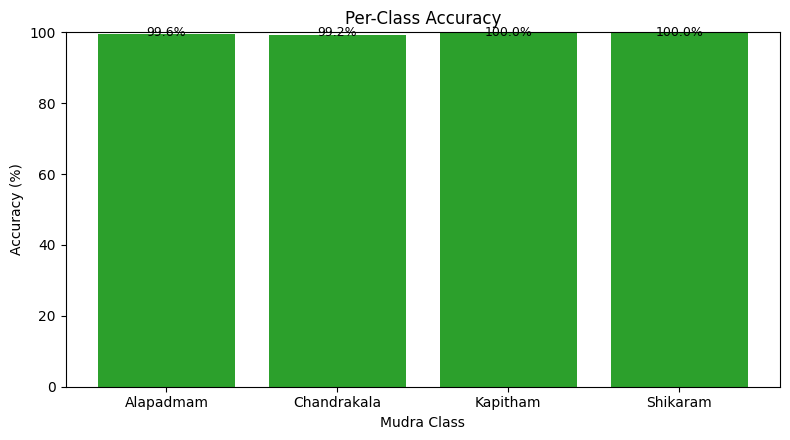

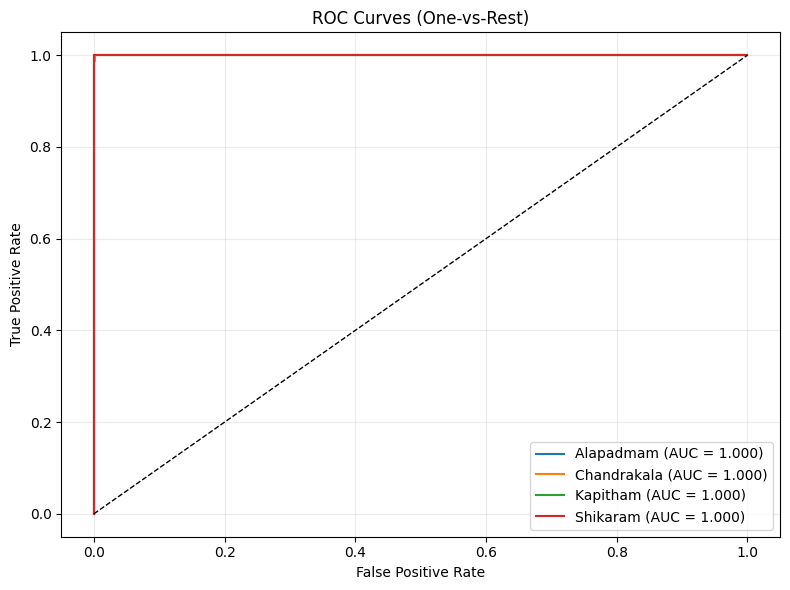

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

from sklearn.metrics import auc, roc_curve
from sklearn.preprocessing import label_binarize

print("\n📊 Evaluating with visual metrics on validation split...")

y_true = []
y_pred = []
y_prob = []

for images, labels in val_ds:
    probs = model.predict(images, verbose=0)
    preds = np.argmax(probs, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(preds)
    y_prob.extend(probs)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

num_classes = len(class_names)
conf_matrix = tf.math.confusion_matrix(y_true, y_pred, num_classes=num_classes).numpy()
overall_acc = (y_true == y_pred).mean() * 100

print(f"Overall validation accuracy: {overall_acc:.2f}%\n")
print("Confusion matrix:")
print(conf_matrix)
print()

class_acc_values = []
for index, class_name in enumerate(class_names):
    total = conf_matrix[index].sum()
    correct = conf_matrix[index, index]
    class_acc = (correct / total * 100) if total else 0.0
    class_acc_values.append(class_acc)
    print(f"{class_name}: {correct}/{total} correct ({class_acc:.2f}%)")

# 1) Confusion matrix as image
plt.figure(figsize=(7, 6))
plt.imshow(conf_matrix, cmap="Blues")
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(np.arange(num_classes), class_names, rotation=20)
plt.yticks(np.arange(num_classes), class_names)

max_value = conf_matrix.max() if conf_matrix.size else 0
for i in range(num_classes):
    for j in range(num_classes):
        value = conf_matrix[i, j]
        text_color = "white" if value > max_value / 2 else "black"
        plt.text(j, i, str(value), ha="center", va="center", color=text_color)

plt.colorbar(fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

# 2) Frequency image: true vs predicted class frequency (upload vs live style)
true_counts = np.bincount(y_true, minlength=num_classes)
pred_counts = np.bincount(y_pred, minlength=num_classes)

x = np.arange(num_classes)
width = 0.38

plt.figure(figsize=(8, 4.5))
plt.bar(x - width / 2, true_counts, width=width, label="Upload/True Frequency", color="#1f77b4")
plt.bar(x + width / 2, pred_counts, width=width, label="Live/Predicted Frequency", color="#ff7f0e")
plt.xticks(x, class_names, rotation=15)
plt.xlabel("Mudra Class")
plt.ylabel("Count")
plt.title("Class Frequency: Upload(True) vs Live(Predicted)")
plt.legend()
plt.tight_layout()
plt.show()

# 3) Class accuracy as image
plt.figure(figsize=(8, 4.5))
plt.bar(class_names, class_acc_values, color="#2ca02c")
plt.ylim(0, 100)
plt.xlabel("Mudra Class")
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy")
for i, score in enumerate(class_acc_values):
    plt.text(i, min(score + 1.0, 99.0), f"{score:.1f}%", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

# 4) ROC curve image (one-vs-rest)
y_true_bin = label_binarize(y_true, classes=np.arange(num_classes))

plt.figure(figsize=(8, 6))
for i, class_name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_true_bin[:, i], y_prob[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f"{class_name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", linewidth=1)
plt.title("ROC Curves (One-vs-Rest)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()